# Laboratorio di Analisi Numerica
## Lezione 8

Cecilia Pagliantini <cecilia.pagliantini@unipi.it>  
Leonardo Robol <leonardo.robol@unipi.it>  
18-19 novembre 2026

*Aggiornamento non completato*

> **Quantità di esercizi:** in questa dispensa ci sono *più esercizi* di quanti uno studente medio riesca a farne durante una lezione di laboratorio, specialmente tenendo conto anche degli esercizi facoltativi. Questo perché è pensata per “tenere impegnati” per tutta la lezione anche quegli studenti che già hanno un solido background di programmazione.
>
> Quindi fate gli esercizi che riuscite, partendo da quelli *non* segnati come facoltativi, e non preoccupatevi se non li finite tutti!

Questa lezione usa `LinearAlgebra` e `Plots`. Se necessario eseguite una sola volta `using Pkg; Pkg.add("Plots")`. Per alcuni esercizi facoltativi useremo anche `Polynomials` e `Colors`, con istruzioni nelle sezioni corrispondenti.

Eseguite le celle dall’alto verso il basso e completate gli esercizi negli spazi predisposti. Le chiamate alle funzioni da scrivere sono commentate: togliete `#` dopo averle definite.

In [1]:
using LinearAlgebra
using Plots

## 1. Frattali di Newton

In questo laboratorio disegneremo i bacini di attrazione del metodo di Newton nel piano complesso: ogni punto iniziale viene colorato secondo la radice a cui converge, come nell'immagine sotto. Il confine tra i bacini ha una struttura molto complessa.

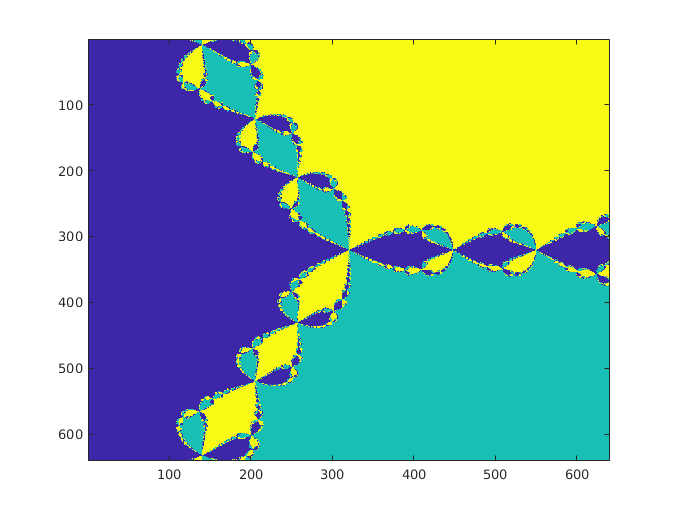
Figura: Bacini di attrazione per il polinomio $x^3 + 1$.

Cominciamo dividendo il problema in sottoproblemi più semplici.

### 1.1. Manipolazione di polinomi

Rappresentiamo un generico polinomio con il vettore dei coefficienti in **ordine decrescente**. Per esempio $x^3+2x-1$ corrisponde a `[1, 0, 2, -1]`. Si noti che ad un polinomio di grado $n$ corrisponde un vettore di lunghezza $n+1$.

Il metodo di Horner per valutare un polinomio associa i prodotti, ad esempio per il grado quattro, come

$$p(x)=(((a_4x+a_3)x+a_2)x+a_1)x+a_0.$$

### Esercizio 1

Si scriva una funzione `horner(p, x)` che valuti il polinomio con il metodo di Horner. L'input `p` corrisponde al vettore dei coefficienti del polinomio. La funzione deve funzionare anche per `x` complesso. Confrontate il risultato con la valutazione diretta su qualche polinomio piccolo.

In [14]:
# Scrivete qui la soluzione la funzione horner(p, x)

### Esercizio 2

Si scriva una funzione `derivata(p)` che, dato il vettore dei coefficienti di un polinomio, restituisce il vettore dei coefficienti della sua derivata, mantenendo l'ordine decrescente. Gestite anche un polinomio costante, per esempio restituendo `[0.0]`.

In [15]:
# Scrivete qui la soluzione la funzione derivata(p)

### 1.2. Metodo di Newton

Il metodo di Newton per trovare le radici di un polinomio p è definito mediante l’iterazione

$$x_{k+1}=x_k-\frac{p(x_k)}{p'(x_k)},\qquad k\geq 0$$

con $x_0$ dato.

### Esercizio 3

Si scriva una funzione `newton(p, x0)` che esegue il metodo di Newton sul polinomio `p` partendo dal punto iniziale `x0`. Come criterio di arresto, si puo usare quello che termina quando $|p(x)|\leq10^{-12}$.
Una convenzione possibile è restituire `NaN + NaN*im` se il metodo non converge.

In [16]:
# Scrivete qui la funzione newton(p, x0)

Si testi l'implementazione del metodo di Newton sul polinomio $p(x)=x^3+1$. Quali sono le sue radici? Riuscite a trovare un punto iniziale che converga a ciascuna di esse?

**Julia:** l’unità immaginaria si scrive `im`, ad esempio `2 + 3im`. Usate `abs(z)` per il modulo e `isfinite(z)` per controllare il risultato.

In [17]:
p = [1.0, 0, 0, 1]
# newton(p, -2.0)
# newton(p, 1.0 + 1.0im)
# newton(p, 1.0 - 1.0im)
# newton(p, 0.0)  # caso da gestire: derivata nulla

4-element Vector{Float64}:
 1.0
 0.0
 0.0
 1.0

### 1.3. Disegnare una matrice

Con `Plots`, la funzione `heatmap(A)` prende come parametro una matrice $A$ e associa un colore a ogni entrata della matrice. La scala `:viridis` va da colori scuri a giallo per valori crescenti.

Per visualizzare la prima riga in alto, come `imagesc` di MATLAB, usate `yflip=true`.

In [ ]:
heatmap(rand(100, 100); color=:viridis, yflip=true, aspect_ratio=:equal)

Si provino anche la matrice identità di ordine $100$ e la matrice `laplacian` implementa nei laboratori precedenti.

### 1.4. Frattale di Newton

Per disegnare il frattale di Newton relativo al polinomio $p(x) = x^3 + 1$, abbiamo bisogno di una funzione che "decida" a quale valore il metodo converge.

### Esercizio 4

Si scriva una funzione `decidi(x)` che restituisce $1$, $2$ oppure $3$ a seconda che $x$ sia più vicino a

$$-1,\qquad \frac12-\frac{\sqrt3}{2}i,\qquad \frac12+\frac{\sqrt3}{2}i.$$

Confrontate le distanze con `abs`; `argmin` restituisce l’indice del minimo in un vettore. Questa funzione classifica solo valori finiti provenienti da iterazioni convergenti.

In [8]:
# Scrivete qui la funzione decidi(x)

### Esercizio 5

Si scriva una funzione `newtonfractal()` che restituisce una matrice `img` di dimensione $101\times101$ calcolata con i passi seguenti:

1. Generate il vettore `griglia` contenente $101$ valori equispaziati nell'intervallo $[-2,2]$.
2. Per ogni coppia $1\leq s, t\leq 101$, ponete `z0 = griglia[s] + im*griglia[t]`.
3. Applicate il metodo di Newton a $x^3+1$ partendo dal punto `z0`.
4. Salvate in `img[t, s]` il valore di `decidi` per la radice trovata.
5. Restituite `img`.

Riservate il valore `0` ai punti per cui il metodo non converge.
Fate attenzione al fatto che **la griglia contiene l’origine**.

Visualizzate il risultato con gli assi reale e immaginario.

In [18]:
# Scrivete qui la funzione newtonfractal()

In [19]:
griglia = range(-2, 2; length=101)
# img = newtonfractal()
# heatmap(griglia, griglia, img; color=cgrad([:black, :red, :green, :blue], categorical=true),
#         clims=(-0.5, 3.5), colorbar_ticks=0:3, aspect_ratio=:equal,
#         xlabel="Re(z₀)", ylabel="Im(z₀)", yflip=false)

-2.0:0.04:2.0

## 2. Esercizi facoltativi

### Esercizio 6 (facoltativo)

Generate i frattali di Newton di altri polinomi. Generalizzate le funzioni affinché ricevano il polinomio e la lista delle sue radici.

Per trovare le radici potete usare `Polynomials.jl`: installatelo una sola volta con `using Pkg; Pkg.add("Polynomials")`. **Attenzione:** `Polynomial` usa coefficienti in ordine crescente, opposto a quello scelto in questa lezione. Convertite con `reverse(p)`.

A differenza di MATLAB, la funzione `roots` non fa parte della libreria standard Julia.

In [20]:
# Scrivete qui la soluzione per l’esercizio 6

In [21]:
# Dopo aver installato Polynomials:
# import Polynomials
# q = Polynomials.Polynomial(reverse([1.0, -1, -1]))
# Polynomials.roots(q)  # radici di x² - x - 1
# q(2.0)               # valutazione, equivalente a polyval
# dq = Polynomials.derivative(q)  # equivalente a polyder

### 2.1. Frattale di Julia

Per un numero complesso $c$, consideriamo la successione $z_{k+1}=z_k^2+c$. L’insieme dei punti iniziali per cui la successione rimane limitata è l’**insieme di Julia pieno**; il suo bordo è l’insieme di Julia.

### Esercizio 7 (facoltativo)

Si scriva una funzione `julia_fractal(c)` che:

1. Genera 101 valori equispaziati in $[-2,2]$.
2. Per ogni $z_0=\text{griglia}[s]+i\,\text{griglia}[t]$, applica per dieci volte la funzione $f(z)=z^2+c$.
3. Salva in `img[t,s]` l'arcotangente del modulo del numero complesso calcolato.
4. Restituisce la matrice `img`.

L’arcotangente comprime l’enorme variazione dei moduli. Gestite l’eventuale overflow: per un punto già "sfuggito" potete assegnare il valore limite $\pi/2$, senza continuare a operare su `Inf` fino a generare `NaN`.

Si provi la funzione con i seguenti valori di $c$: $c=1-\phi$, $(\phi-2)+i(\phi-1)$, $i$, $-0.8+0.156i$, dove $\phi=(1+\sqrt5)/2$.

In [22]:
# Scrivete qui la funzione julia_fractal(c)

In [23]:
phi = (1 + sqrt(5)) / 2
parametri = [1-phi, (phi-2)+im*(phi-1), im, -0.8+0.156im]
# for c in parametri
#     display(heatmap(griglia, griglia, julia_fractal(c);
#                     aspect_ratio=:equal, title="c = $c", yflip=false))
# end

4-element Vector{ComplexF64}:
 -0.6180339887498949 + 0.0im
 -0.3819660112501051 + 0.6180339887498949im
                 0.0 + 1.0im
                -0.8 + 0.156im

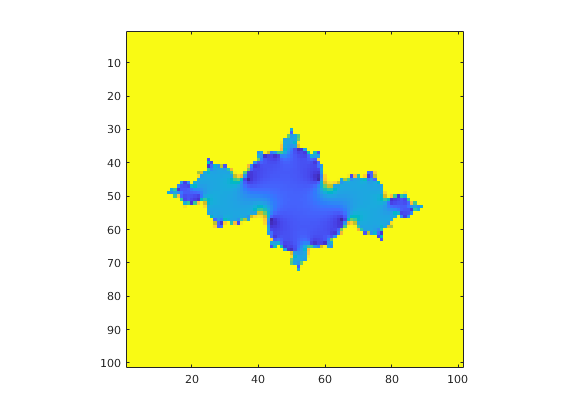

Un esempio di visualizzazione del frattale di Julia.

### Esercizio 8 (facoltativo)

Modificate `disegna_newton` per produrre una seconda immagine a colori, con tonalità determinata dalla radice e intensità dal numero di iterazioni. Gestite immagini rettangolari e altri polinomi.

In Julia è comodo rappresentare un’immagine con una matrice di colori `RGB`, invece del tensore numerico a tre canali usato in MATLAB. Installate `Colors` con `using Pkg; Pkg.add("Colors")`. Con `using Colors`, `RGB(r, g, b)` costruisce un colore con canali in `[0,1]`; una matrice di questi colori si visualizza con `plot(img2; axis=false, ticks=false)`.

Progettate `disegna_newton(m, n)` affinché restituisca `img, img2`, e provate `img, img2 = disegna_newton(640, 1024)`. Annotate il trattamento dei punti non convergenti.

In [24]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 9

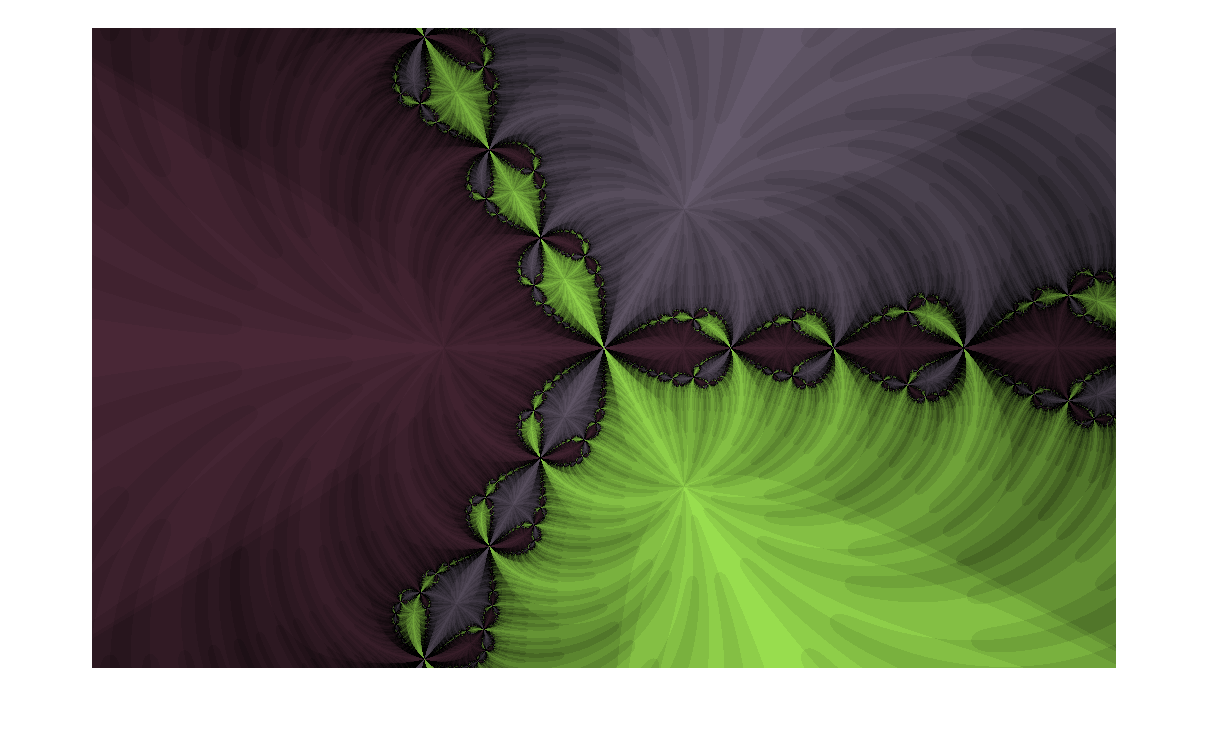

Riferimenti per gli adattamenti: [Polynomials.jl: coefficienti, valutazione, derivate e radici](https://juliamath.github.io/Polynomials.jl/stable/).